# 07 — Decision Tree Classification

## Objective
This notebook trains and evaluates a Decision Tree classifier to distinguish VMO-dominant and VL-dominant EMG activity using extracted signal features.

## Workflow
1. Load the window-level feature dataset from Google Sheets.
2. Remove identifier columns and selected ratio features.
3. Encode the activity labels and separate features from labels.
4. Impute missing values and split the dataset into stratified training and testing sets.
5. Train a Decision Tree classifier with a maximum depth of five and class weighting.
6. Evaluate performance using accuracy, balanced accuracy, a classification report, and a confusion matrix.
7. Visualise the confusion matrix and feature importance.
8. Examine the class distribution and apply the model to features extracted from a user-provided raw EMG CSV.

## Output
Classification metrics, a confusion matrix, feature-importance visualisation, class-distribution statistics, and an exploratory raw-EMG prediction pipeline.

## Interpretation note
The model predicts categories defined by the dataset's labels. These predictions are not clinically validated diagnoses and should not be interpreted as confirmed PFPS risk.


RESULTS
Accuracy: 0.8933333333333333
Balanced Accuracy: 0.8761248002691111

Classification Report:
               precision    recall  f1-score   support

VMO_dominant       0.62      0.85      0.71        47
 VL_dominant       0.97      0.90      0.93       253

    accuracy                           0.89       300
   macro avg       0.79      0.88      0.82       300
weighted avg       0.91      0.89      0.90       300


Confusion Matrix:

            Predicted VMO  Predicted VL
Actual VMO             40             7
Actual VL              25           228


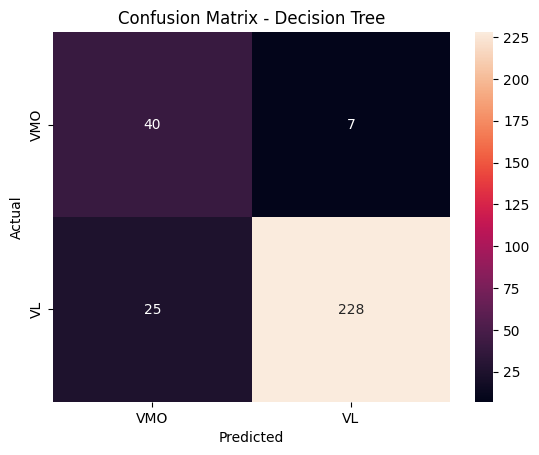

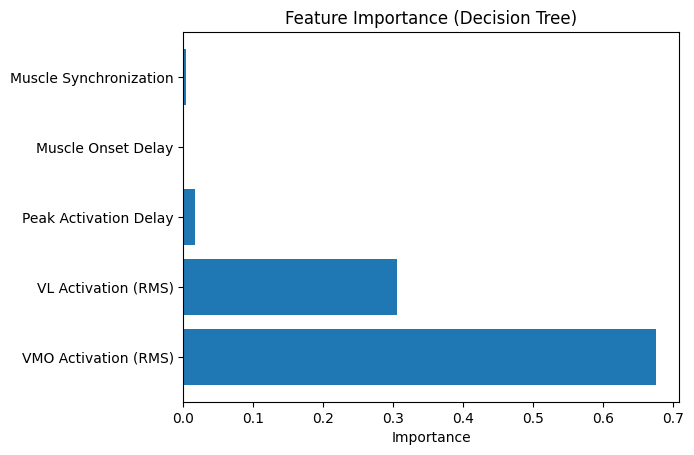


Class Distribution:
VL Dominant: 841 (84.3%)
VMO Dominant: 157 (15.7%)

Model : Decision Tree Classifier

Upload CSV file (any column names allowed)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.impute import SimpleImputer

# -----------------------------
# 1. LOAD DATA
# -----------------------------
sheet_id = "1jpnqHp_Eaq61QzrzK0xavPfnT9xddWWyMdb5OAhd5Iw"
gid = "1292720919"

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"
df = pd.read_csv(url)

# -----------------------------
# 2. CLEAN DATA
# -----------------------------
df = df.drop(columns=["window_id", "start_index", "end_index"])
df = df.drop(columns=["RMS_ratio", "iEMG_ratio"])

# -----------------------------
# 3. LABELS
# -----------------------------
df["Status"] = df["Status"].str.strip().str.lower()

y = df["Status"].map({
    "vmo_dominant": 0,
    "vl_dominant": 1
})

X = df.drop(columns=["Status"])

# -----------------------------
# 4. HANDLE MISSING
# -----------------------------
imputer = SimpleImputer(strategy="mean")
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# -----------------------------
# 5. SPLIT (STRATIFIED)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# -----------------------------
# 6. SCALING (kept for consistency)
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 7. MODEL
# -----------------------------
model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

labels = ["VMO_dominant","VL_dominant"]

# -----------------------------
# 8. EVALUATION
# -----------------------------
preds = model.predict(X_test_scaled)

print("\nRESULTS")
print("Accuracy:", accuracy_score(y_test, preds))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, preds))

print("\nClassification Report:\n",
      classification_report(y_test, preds, target_names=labels))

cm = confusion_matrix(y_test, preds)

cm_df = pd.DataFrame(cm,
                     index=["Actual VMO", "Actual VL"],
                     columns=["Predicted VMO", "Predicted VL"])

print("\nConfusion Matrix:\n")
print(cm_df)

# -----------------------------
# 9. HEATMAP
# -----------------------------
plt.figure()
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["VMO", "VL"],
            yticklabels=["VMO", "VL"])
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# -----------------------------
# 10. FEATURE IMPORTANCE
# -----------------------------
importances = model.feature_importances_
feature_names = [
    "VMO Activation (RMS)",
    "VL Activation (RMS)",
    "Peak Activation Delay",
    "Muscle Onset Delay",
    "Muscle Synchronization"
]

plt.figure()
plt.barh(feature_names, importances)
plt.title("Feature Importance (Decision Tree)")
plt.xlabel("Importance")
plt.show()

# -----------------------------
# 11. CLASS DISTRIBUTION
# -----------------------------
total = len(y)
vl_count = (y == 1).sum()
vmo_count = (y == 0).sum()

print("\nClass Distribution:")
print(f"VL Dominant: {vl_count} ({vl_count/total:.1%})")
print(f"VMO Dominant: {vmo_count} ({vmo_count/total:.1%})")

print("\nModel : Decision Tree Classifier")


# ============================================================
#  12. RAW EMG PIPELINE
# ============================================================

# ---- COLAB DETECTION ----
try:
    from google.colab import files
    COLAB = True
except:
    COLAB = False

# ---- INPUT ----
def get_user_emg():
    if COLAB:
        print("\nUpload CSV file (any column names allowed)")
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
    else:
        filename = input("Enter CSV file path: ")

    df_raw = pd.read_csv(filename)

    df_raw.columns = df_raw.columns.str.strip().str.lower()

    print("\nDetected columns:", df_raw.columns.tolist())

    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns

    if len(numeric_cols) < 2:
        raise ValueError("CSV must contain at least 2 numeric columns")

    vmo_col = numeric_cols[0]
    vl_col  = numeric_cols[1]


    return df_raw[vmo_col].values, df_raw[vl_col].values


# ---- WINDOWING ----
def window_signal(signal, window_size=200, step=100):
    return [
        signal[i:i+window_size]
        for i in range(0, len(signal) - window_size + 1, step)
    ]


# ---- FEATURE EXTRACTION ----
def extract_features(vmo_win, vl_win):

    vmo_rect = np.abs(vmo_win)
    vl_rect  = np.abs(vl_win)

    vmo_rms = np.sqrt(np.mean(vmo_rect**2))
    vl_rms  = np.sqrt(np.mean(vl_rect**2))

    peak_delay = np.argmax(vl_rect) - np.argmax(vmo_rect)

    onset_vmo = np.argmax(vmo_rect > 0.1*np.max(vmo_rect))
    onset_vl  = np.argmax(vl_rect > 0.1*np.max(vl_rect))
    onset_delay = onset_vl - onset_vmo

    sync = np.corrcoef(vmo_rect, vl_rect)[0,1]

    return [vmo_rms, vl_rms, peak_delay, onset_delay, sync]


# ---- PREDICTION PIPELINE ----
def predict_from_raw():
    vmo_signal, vl_signal = get_user_emg()

    if len(vmo_signal) < 200:
        raise ValueError("Signal too short")

    vmo_windows = window_signal(vmo_signal)
    vl_windows  = window_signal(vl_signal)

    features = []

    for vmo_w, vl_w in zip(vmo_windows, vl_windows):
        features.append(extract_features(vmo_w, vl_w))

    if len(features) == 0:
        raise ValueError("No windows generated")

    features_df = pd.DataFrame(features, columns=X.columns)

    features_df = pd.DataFrame(imputer.transform(features_df), columns=X.columns)
    features_scaled = scaler.transform(features_df)

    preds = model.predict(features_scaled)

    final_pred = np.bincount(preds).argmax()

    label_map = {
        0: "VMO Dominant",
        1: "VL Dominant (Possible PFPS Risk)"
    }

    print("\nFINAL PREDICTION:", label_map[final_pred])


# -----------------------------
# RUN
# -----------------------------
predict_from_raw()